In [ ]:
library(DESeq2)
library(pheatmap)
library(tximport)
library(ggplot2)
library(clusterProfiler)
library(org.Mm.eg.db)
library(clusterProfiler)
library(biomaRt)
library(reshape2) 
library(cowplot)  
library(ggrepel)


In [2]:
# folder to strore figures
dir.create('fig', recursive = TRUE)


Warning message in dir.create("fig", recursive = TRUE):
“'fig' already exists”


# Load data

In [ ]:
# Define vectors for each column of the data frame
tx <- c('CONTROL_REP1', 'CONTROL_REP2', 'CONTROL_REP3', 'KO_REP1', 'KO_REP2', 'KO_REP3')
dir <- rep('nf_RNAouts_salmon', length(tx))
condition <- c(rep('Control', 3), rep('Mutant', 3))
batch <- c('Batch1', 'Batch2', 'Batch3', 'Batch1', 'Batch3', 'Batch3')

samps <- data.frame(
  dir = dir,
  sample_id = tx,
  condition = condition,
  batch = batch
)

files <- file.path( samps$dir, "salmon", samps$sample_id, "quant.sf")
names(files) <- samps$sample_id

# Load and process the tx2gene mapping file, keeping only unique entries
tx2gene <- unique(read.table('nf_RNAouts_salmon/salmon/tx2gene.tsv', sep = '\t'))
colnames(tx2gene) <- c('TXNAME', 'GENEID', 'GENENAME')
rownames(tx2gene) <- tx2gene$TXNAME

# Import transcript-level quantifications with tximport, specifying the tx2gene mapping
txi <- tximport(
  files,
  type = "salmon",
  tx2gene = tx2gene[, c("TXNAME", "GENENAME")],
  countsFromAbundance = "lengthScaledTPM",
  ignoreTxVersion = TRUE
)

head(files)


In [4]:
# Create a metadata DataFrame for Deseq2
meta <- data.frame(
  samps,
  row.names = colnames(txi$counts)
)

# Set 'Control' as the reference level for the condition factor
meta$condition <- relevel(factor(meta$condition), ref = 'Control')

meta

# Check if all column names in txi$counts are present in and match row names of meta
all(colnames(txi$counts) %in% rownames(meta))
all(colnames(txi$counts) == rownames(meta))


,dir,sample_id,condition,batch
,<chr>,<chr>,<fct>,<chr>
CONTROL_REP1,nf_RNAouts_salmon,CONTROL_REP1,Control,Batch1
CONTROL_REP2,nf_RNAouts_salmon,CONTROL_REP2,Control,Batch2
CONTROL_REP3,nf_RNAouts_salmon,CONTROL_REP3,Control,Batch3
KO_REP1,nf_RNAouts_salmon,KO_REP1,Mutant,Batch1
KO_REP2,nf_RNAouts_salmon,KO_REP2,Mutant,Batch3
KO_REP3,nf_RNAouts_salmon,KO_REP3,Mutant,Batch3


[1] TRUE

[1] TRUE

## DESeq2

In [5]:
# https://hbctraining.github.io/DGE_workshop_salmon/lessons/07_DGE_summarizing_workflow.html
# https://bioconductor.org/packages/release/bioc/manuals/tximport/man/tximport.pdf

In the following, we will use DESeq2 to perform differential gene expression (DGE) analysis and principal component analysis (PCA).

In [6]:
## Create DESeq2Dataset object
dds <- DESeqDataSetFromTximport(txi, colData = meta, design = ~ condition)
cpms <- edgeR::cpm(dds)
keep <- which(rowSums(cpms > 0) >= 3)
dds <- dds[keep,]
rld <- rlog(dds, blind=TRUE)

using just counts from tximport



png 
  2

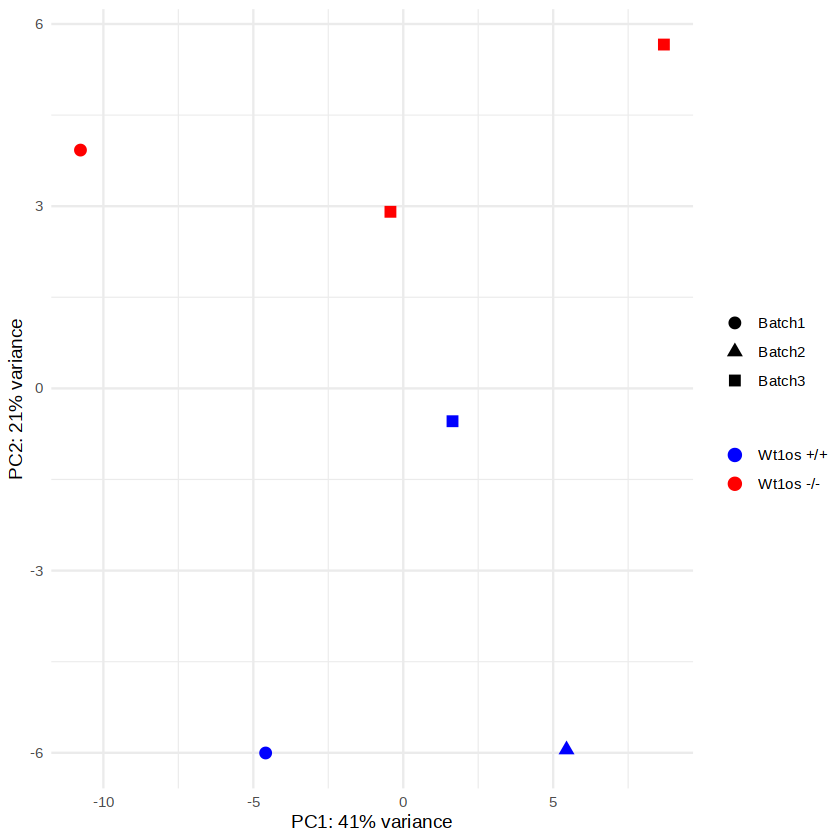

In [7]:
# Extract PCA data from rlog object
pcaData <- plotPCA(rld, intgroup=c("condition", "batch"), returnData=TRUE)

percentVar <- round(100 * attr(pcaData, "percentVar"))

p=ggplot(pcaData, aes(x = PC1, y = PC2, color = condition, shape = batch)) +
  geom_point(size = 3) +
  xlab(paste0("PC1: ", percentVar[1], "% variance")) +
  ylab(paste0("PC2: ", percentVar[2], "% variance")) +
  theme_minimal() +
  theme(legend.position = "right") +
  labs(color = NULL, shape = NULL)  +
  scale_color_manual(values = c("Control" = "blue", "Mutant" = "red"),
                     labels = c("Control" = "Wt1os +/+", "Mutant" = "Wt1os -/-"))

p

pdf("fig/PCA_plot.pdf", width = 4, height = 3)
p
dev.off()

png 
  2

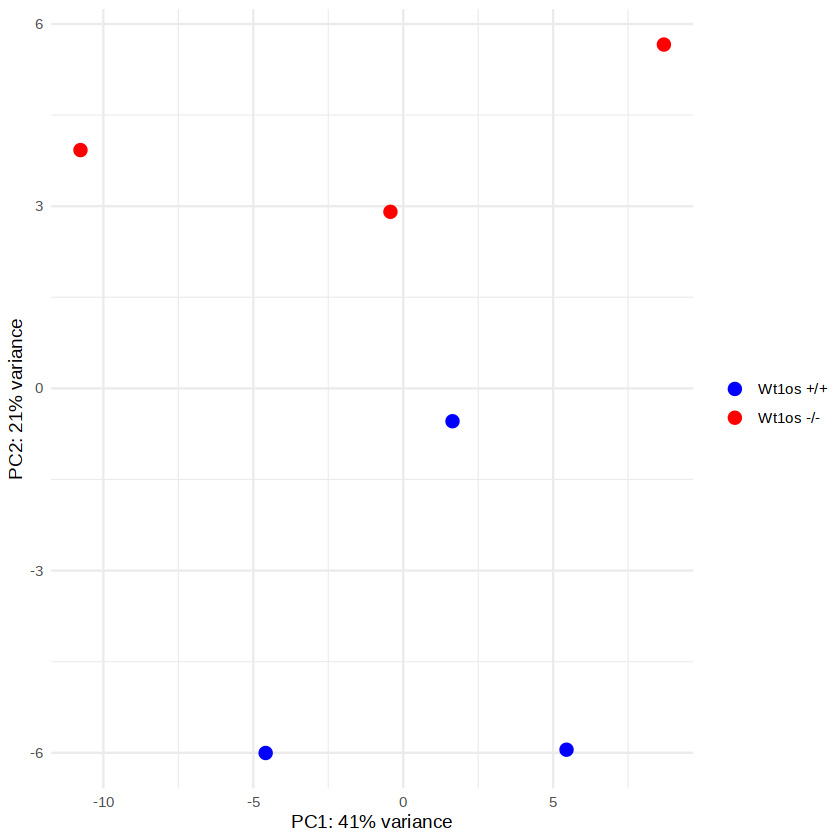

In [8]:
# Extract PCA data from rlog object
pcaData <- plotPCA(rld, intgroup=c("condition"), returnData=TRUE)

percentVar <- round(100 * attr(pcaData, "percentVar"))

p=ggplot(pcaData, aes(x = PC1, y = PC2, color = condition)) +
  geom_point(size = 3) +
  xlab(paste0("PC1: ", percentVar[1], "% variance")) +
  ylab(paste0("PC2: ", percentVar[2], "% variance")) +
  theme_minimal() +
  theme(legend.position = "right") +
  labs(color = NULL, shape = NULL)  +
  scale_color_manual(values = c("Control" = "blue", "Mutant" = "red"),
                     labels = c("Control" = "Wt1os +/+", "Mutant" = "Wt1os -/-"))

p

pdf("fig/PCA_plot2.pdf", width = 4, height = 3)
p
dev.off()

In [9]:
dds <- DESeq(dds)

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



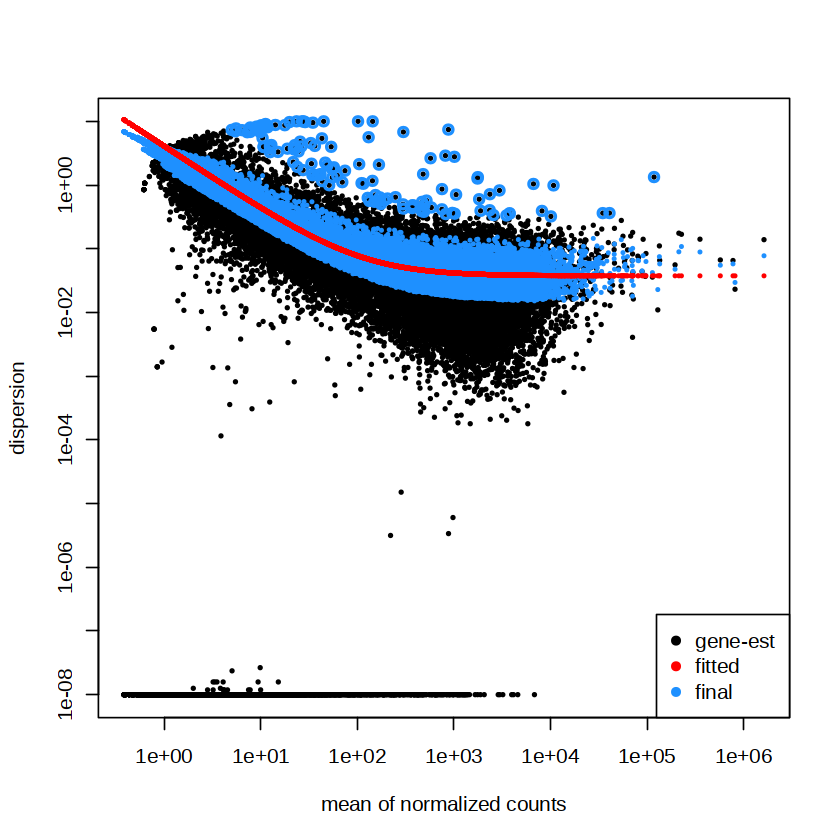

In [10]:
DESeq2::plotDispEsts(dds)

In [11]:
res_tableOE <-DESeq2::results(dds)

res_tableOE %>% 
data.frame() %>% 
View()

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0610005C13Rik,2575.0125077,0.329571899,0.2894831,1.138483979,0.2549184,0.9999072
0610006L08Rik,155.4204219,-0.027735848,0.4095122,-0.067728983,0.9460014,0.9999072
0610009B22Rik,369.9077107,0.118536927,0.2979039,0.397903174,0.6907016,0.9999072
0610009E02Rik,53.7552677,0.401266708,0.4158089,0.965026666,0.3345315,0.9999072
0610009L18Rik,102.9772973,0.054614690,0.3147056,0.173542158,0.8622253,0.9999072
0610010F05Rik,609.7325987,-0.152339868,0.2449429,-0.621940328,0.5339811,0.9999072
0610010K14Rik,515.3980145,-0.118494246,0.2781273,-0.426043214,0.6700764,0.9999072
0610012D04Rik,0.9504018,0.597706177,2.5749214,0.232125993,0.8164402,NA
0610012G03Rik,874.1881367,0.262732877,0.2925077,0.898208331,0.3690745,0.9999072


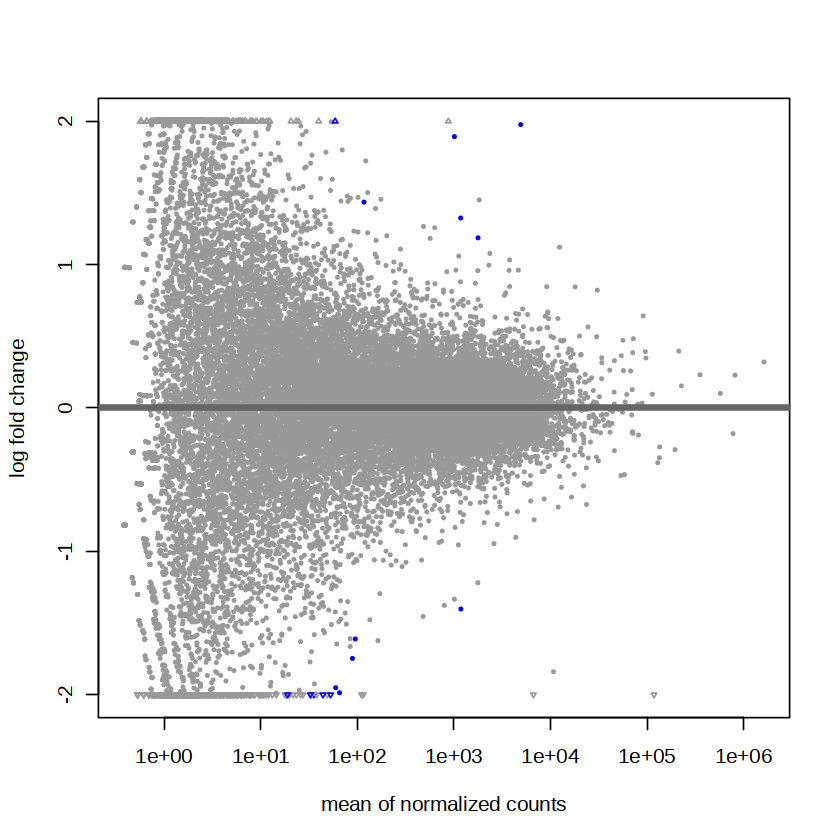

In [12]:
DESeq2::plotMA(res_tableOE, ylim=c(-2,2))

In [13]:
summary(res_tableOE, alpha = 0.05)


out of 25166 with nonzero total read count
adjusted p-value < 0.05
LFC > 0 (up)       : 6, 0.024%
LFC < 0 (down)     : 5, 0.02%
outliers [1]       : 7, 0.028%
low counts [2]     : 4392, 17%
(mean count < 4)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [14]:
sigOE <- res_tableOE %>% data.frame() %>%
        dplyr::filter(padj < 0.1)
sigOE

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Amd2,35.35948,-2.827636,0.6400033,-4.418158,9.954547e-06,2.296956e-02
Angptl4,1773.64610,1.187266,0.2424822,4.896300,9.765789e-07,3.061750e-03
Cenpf,95.12828,-1.611203,0.3908436,-4.122372,3.749910e-05,5.990336e-02
Erdr1,1009.85748,1.893366,0.4375166,4.327529,1.507916e-05,2.846808e-02
Gm10718,52.70978,-3.093941,0.6734160,-4.594398,4.340006e-06,1.126611e-02
Gm15889,1172.91048,1.325345,0.2372851,5.585455,2.330889e-08,1.720918e-04
Gm43302,32.58365,-8.431478,1.2617842,-6.682187,2.354027e-11,4.888609e-07
Gm47283,4909.96621,1.977126,0.4046985,4.885430,1.032034e-06,3.061750e-03
Kcnd1,88.81839,-1.747277,0.4414529,-3.958015,7.557511e-05,9.809176e-02


In [15]:
genes_to_plot <- c("Wt1os", "Wt1")
custom_colors <- c("#007F5F", "#012A4A")

# Function to retrieve, combine, and plot data
create_gene_plot <- function(dds, genes, normalized = FALSE, output_file = "output.pdf", y_label = "Count") {
    combined_data <- data.frame()
    for (gene_name in genes) {
        
        d <- plotCounts(dds, gene = gene_name, intgroup = "condition", returnData = TRUE, normalized = normalized)
        d$sample = rownames(d)
        d$gene <- gene_name        
        combined_data <- rbind(combined_data, d)
    }
    
    p <- ggplot(combined_data, aes(x = condition, y = count, color = condition)) + 
        geom_point(position = position_jitter(w = 0.1, h = 0)) +
        geom_text_repel(aes(label = sample)) + 
        facet_wrap(~ gene, scales = "free_y") +  # Separate panels for each gene if desired
        theme_minimal() +
        scale_color_manual(values = custom_colors) +  # Apply custom colors
        ylab(y_label) +
        xlab("")
    
    pdf(output_file, width = 10, height = 4)
    print(p)
    dev.off()
}

create_gene_plot(
    dds = dds,
    genes = genes_to_plot,
    normalized = FALSE,
    output_file = "fig/Wt1_Wt1os_expression.pdf",
    y_label = "Count"
)

create_gene_plot(
    dds = dds,
    genes = genes_to_plot,
    normalized = TRUE,
    output_file = "fig/Wt1_Wt1os_Normalized_expression.pdf",
    y_label = "Normalized Expression"
)


png 
  2

png 
  2

In [16]:
log_counts <- log2(counts(dds, normalize=TRUE) + 1)[rownames(sigOE), ]
colnames(log_counts) <- gsub("CONTROL", "Wt1os +/+", colnames(log_counts))
colnames(log_counts) <- gsub("KO", "Wt1os -/-", colnames(log_counts))

pdf("fig/DGE_heatmap.pdf", width = 6, height = 6)

ComplexHeatmap::pheatmap(log_counts, legend = TRUE, cluster_rows = T, cluster_cols = FALSE, 
                           scale = 'row',
#                           color = colorRampPalette(c("white", "#005BAC"))(10), 

                         heatmap_legend_param = list(title = "log2(norm.+1)"))
dev.off()

png 
  2

In [17]:
write.csv(txi$counts,'fig/lengthScaledTPM_counts.csv')
write.csv(counts(dds, normalize=T),'fig/Deseq2_normalizedExpression.csv')
write.csv(res_tableOE %>% data.frame() ,'fig/DGE_Deseq2.csv')
txi2 <- tximport(
  files,
  type = "salmon",
  tx2gene = tx2gene[, c("TXNAME", "GENENAME")],
  countsFromAbundance = "no",
  ignoreTxVersion = TRUE
)
write.csv(txi2$counts,'fig/counts.csv')


reading in files with read_tsv

1 
2 
3 
4 
5 
6 


summarizing abundance

summarizing counts

summarizing length

summarizing inferential replicates



# GSEA

'select()' returned 1:1 mapping between keys and columns

Warning message in bitr(d$SYMBOL, fromType = "SYMBOL", toType = "ENTREZID", OrgDb = org.Mm.eg.db):
“15.47% of input gene IDs are fail to map...”
Reading KEGG annotation online: "https://rest.kegg.jp/link/mmu/pathway"...

Reading KEGG annotation online: "https://rest.kegg.jp/list/pathway/mmu"...

Reading KEGG annotation online: "https://rest.kegg.jp/conv/ncbi-geneid/mmu"...

preparing geneSet collections...

GSEA analysis...

Warning message in preparePathwaysAndStats(pathways, stats, minSize, maxSize, gseaParam, :
“There are ties in the preranked stats (2.15% of the list).
The order of those tied genes will be arbitrary, which may produce unexpected results.”
leading edge analysis...

done...

Warning message in cnetplot.enrichResult(x, ...):
“Use 'color.params = list(foldChange = your_value)' instead of 'foldChange'.
 The foldChange parameter will be removed in the next version.”
Scale for size is already present.
Adding anothe

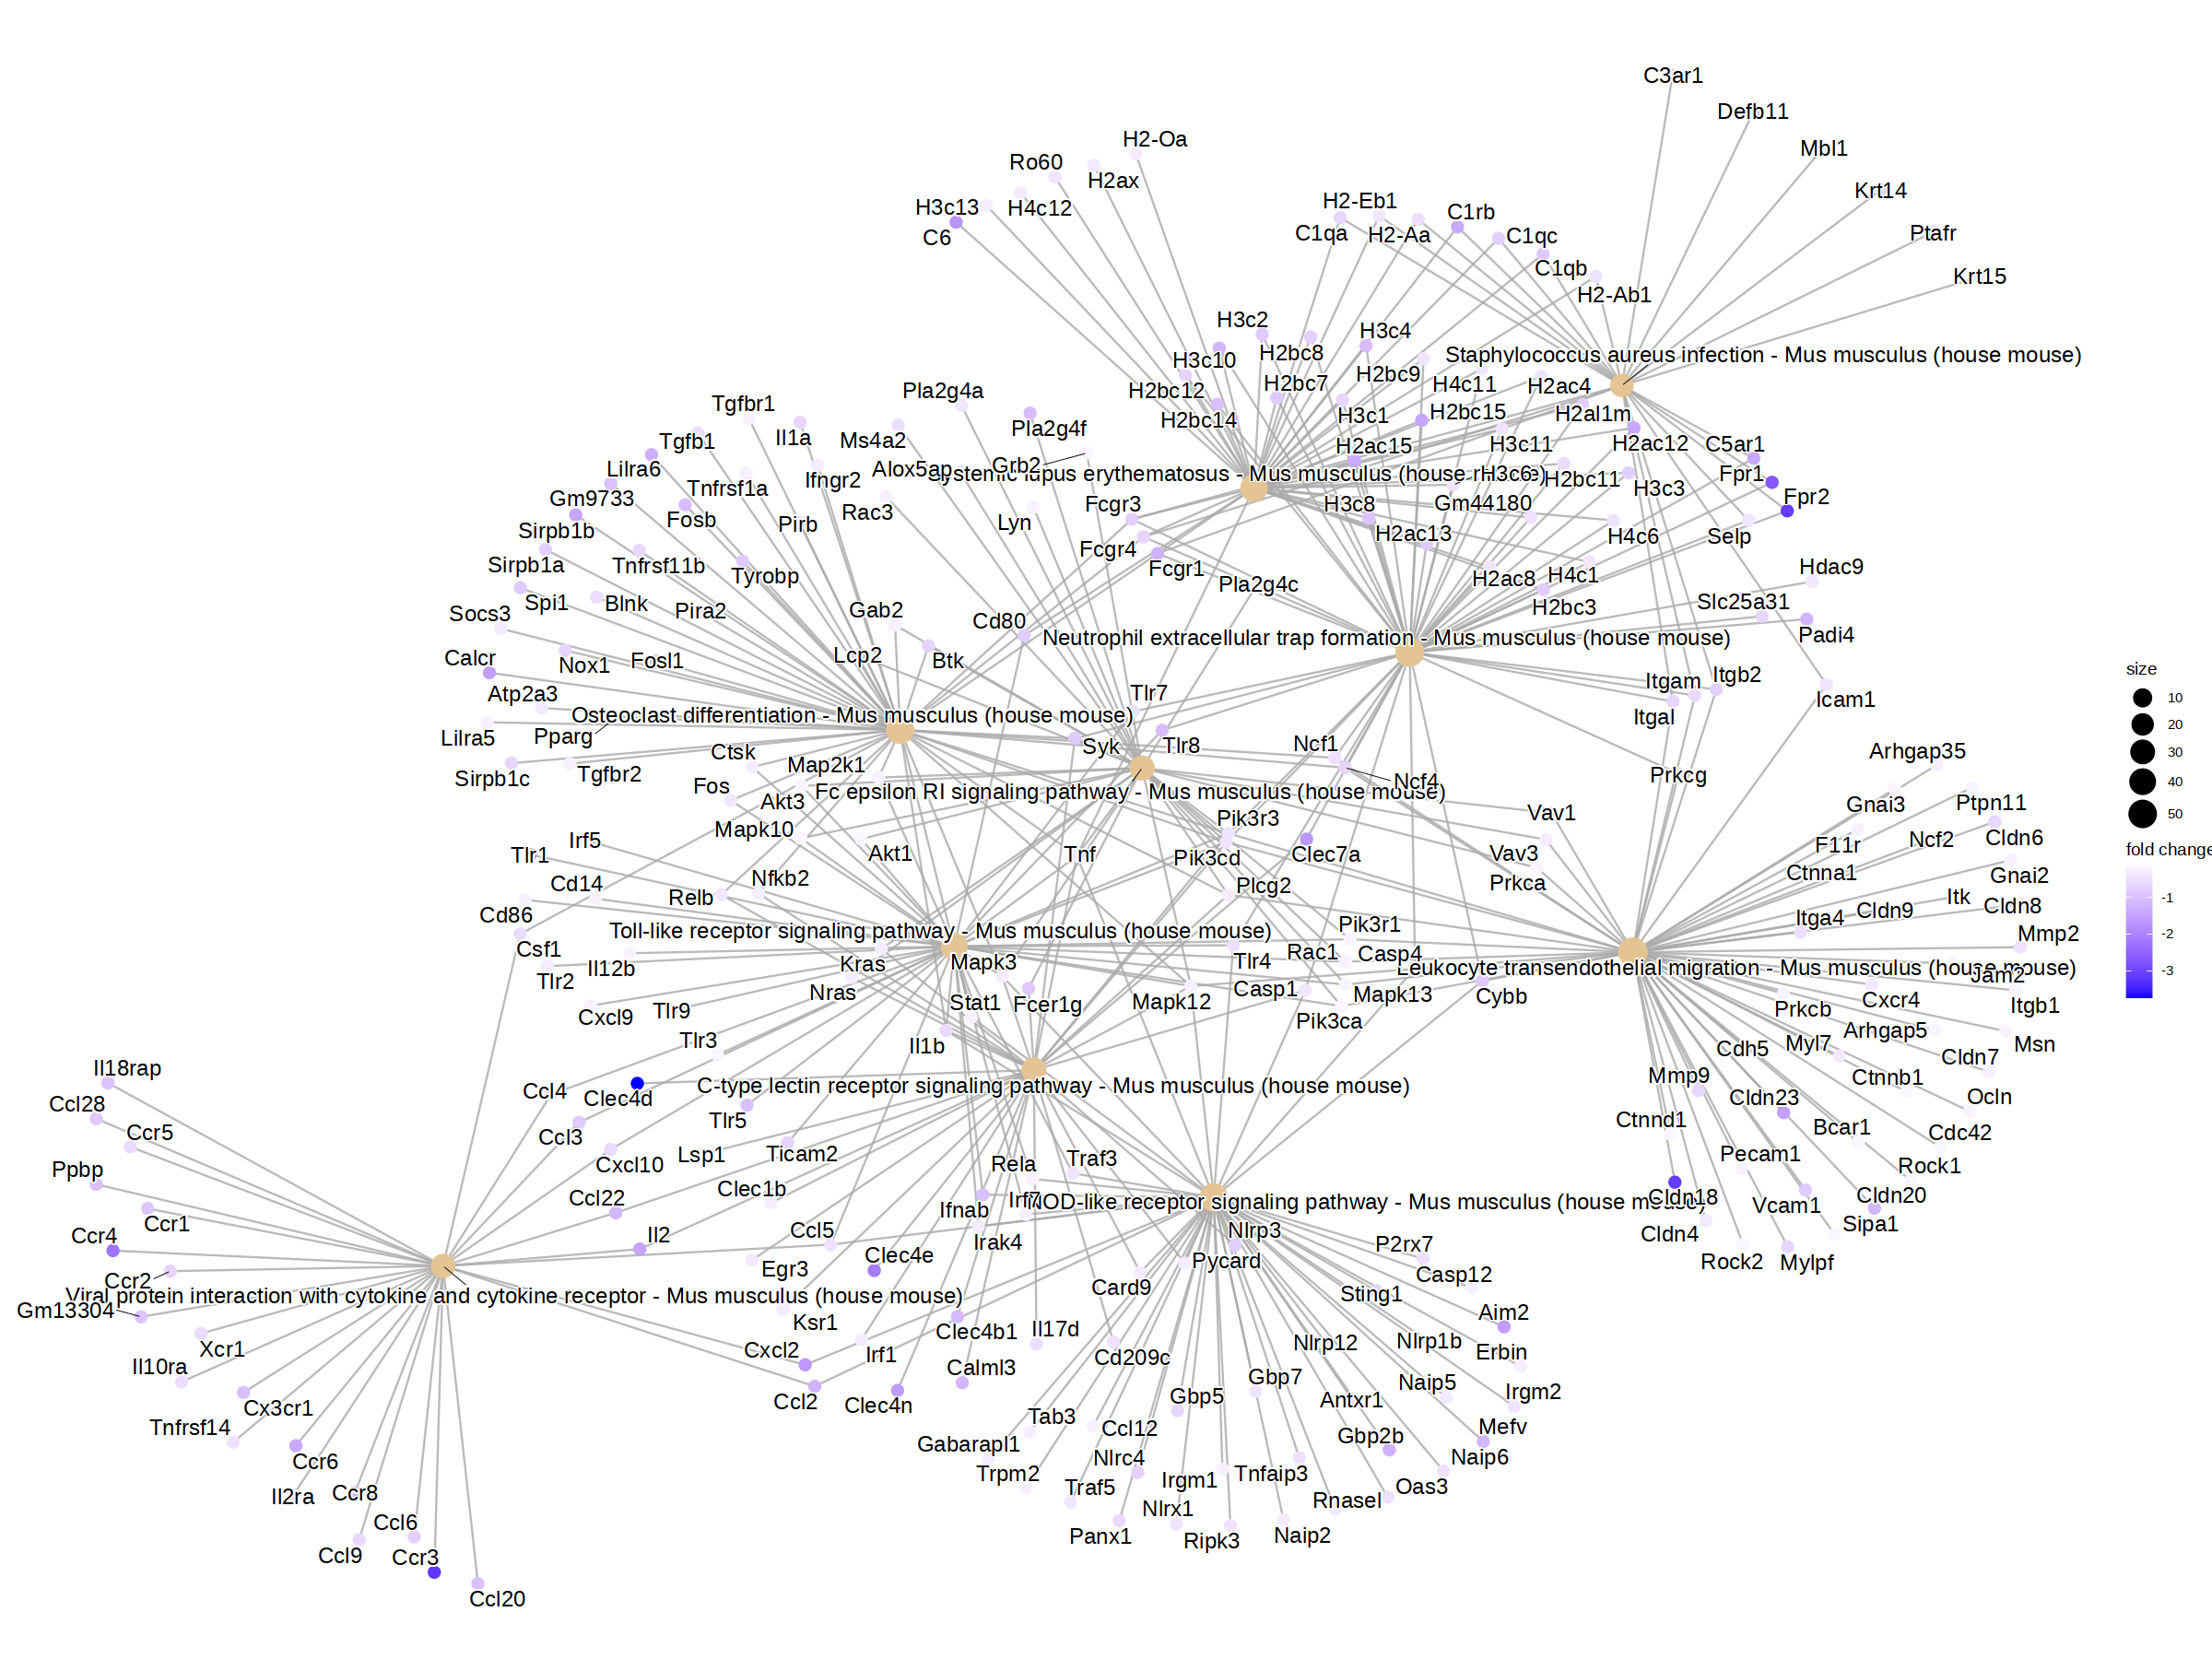

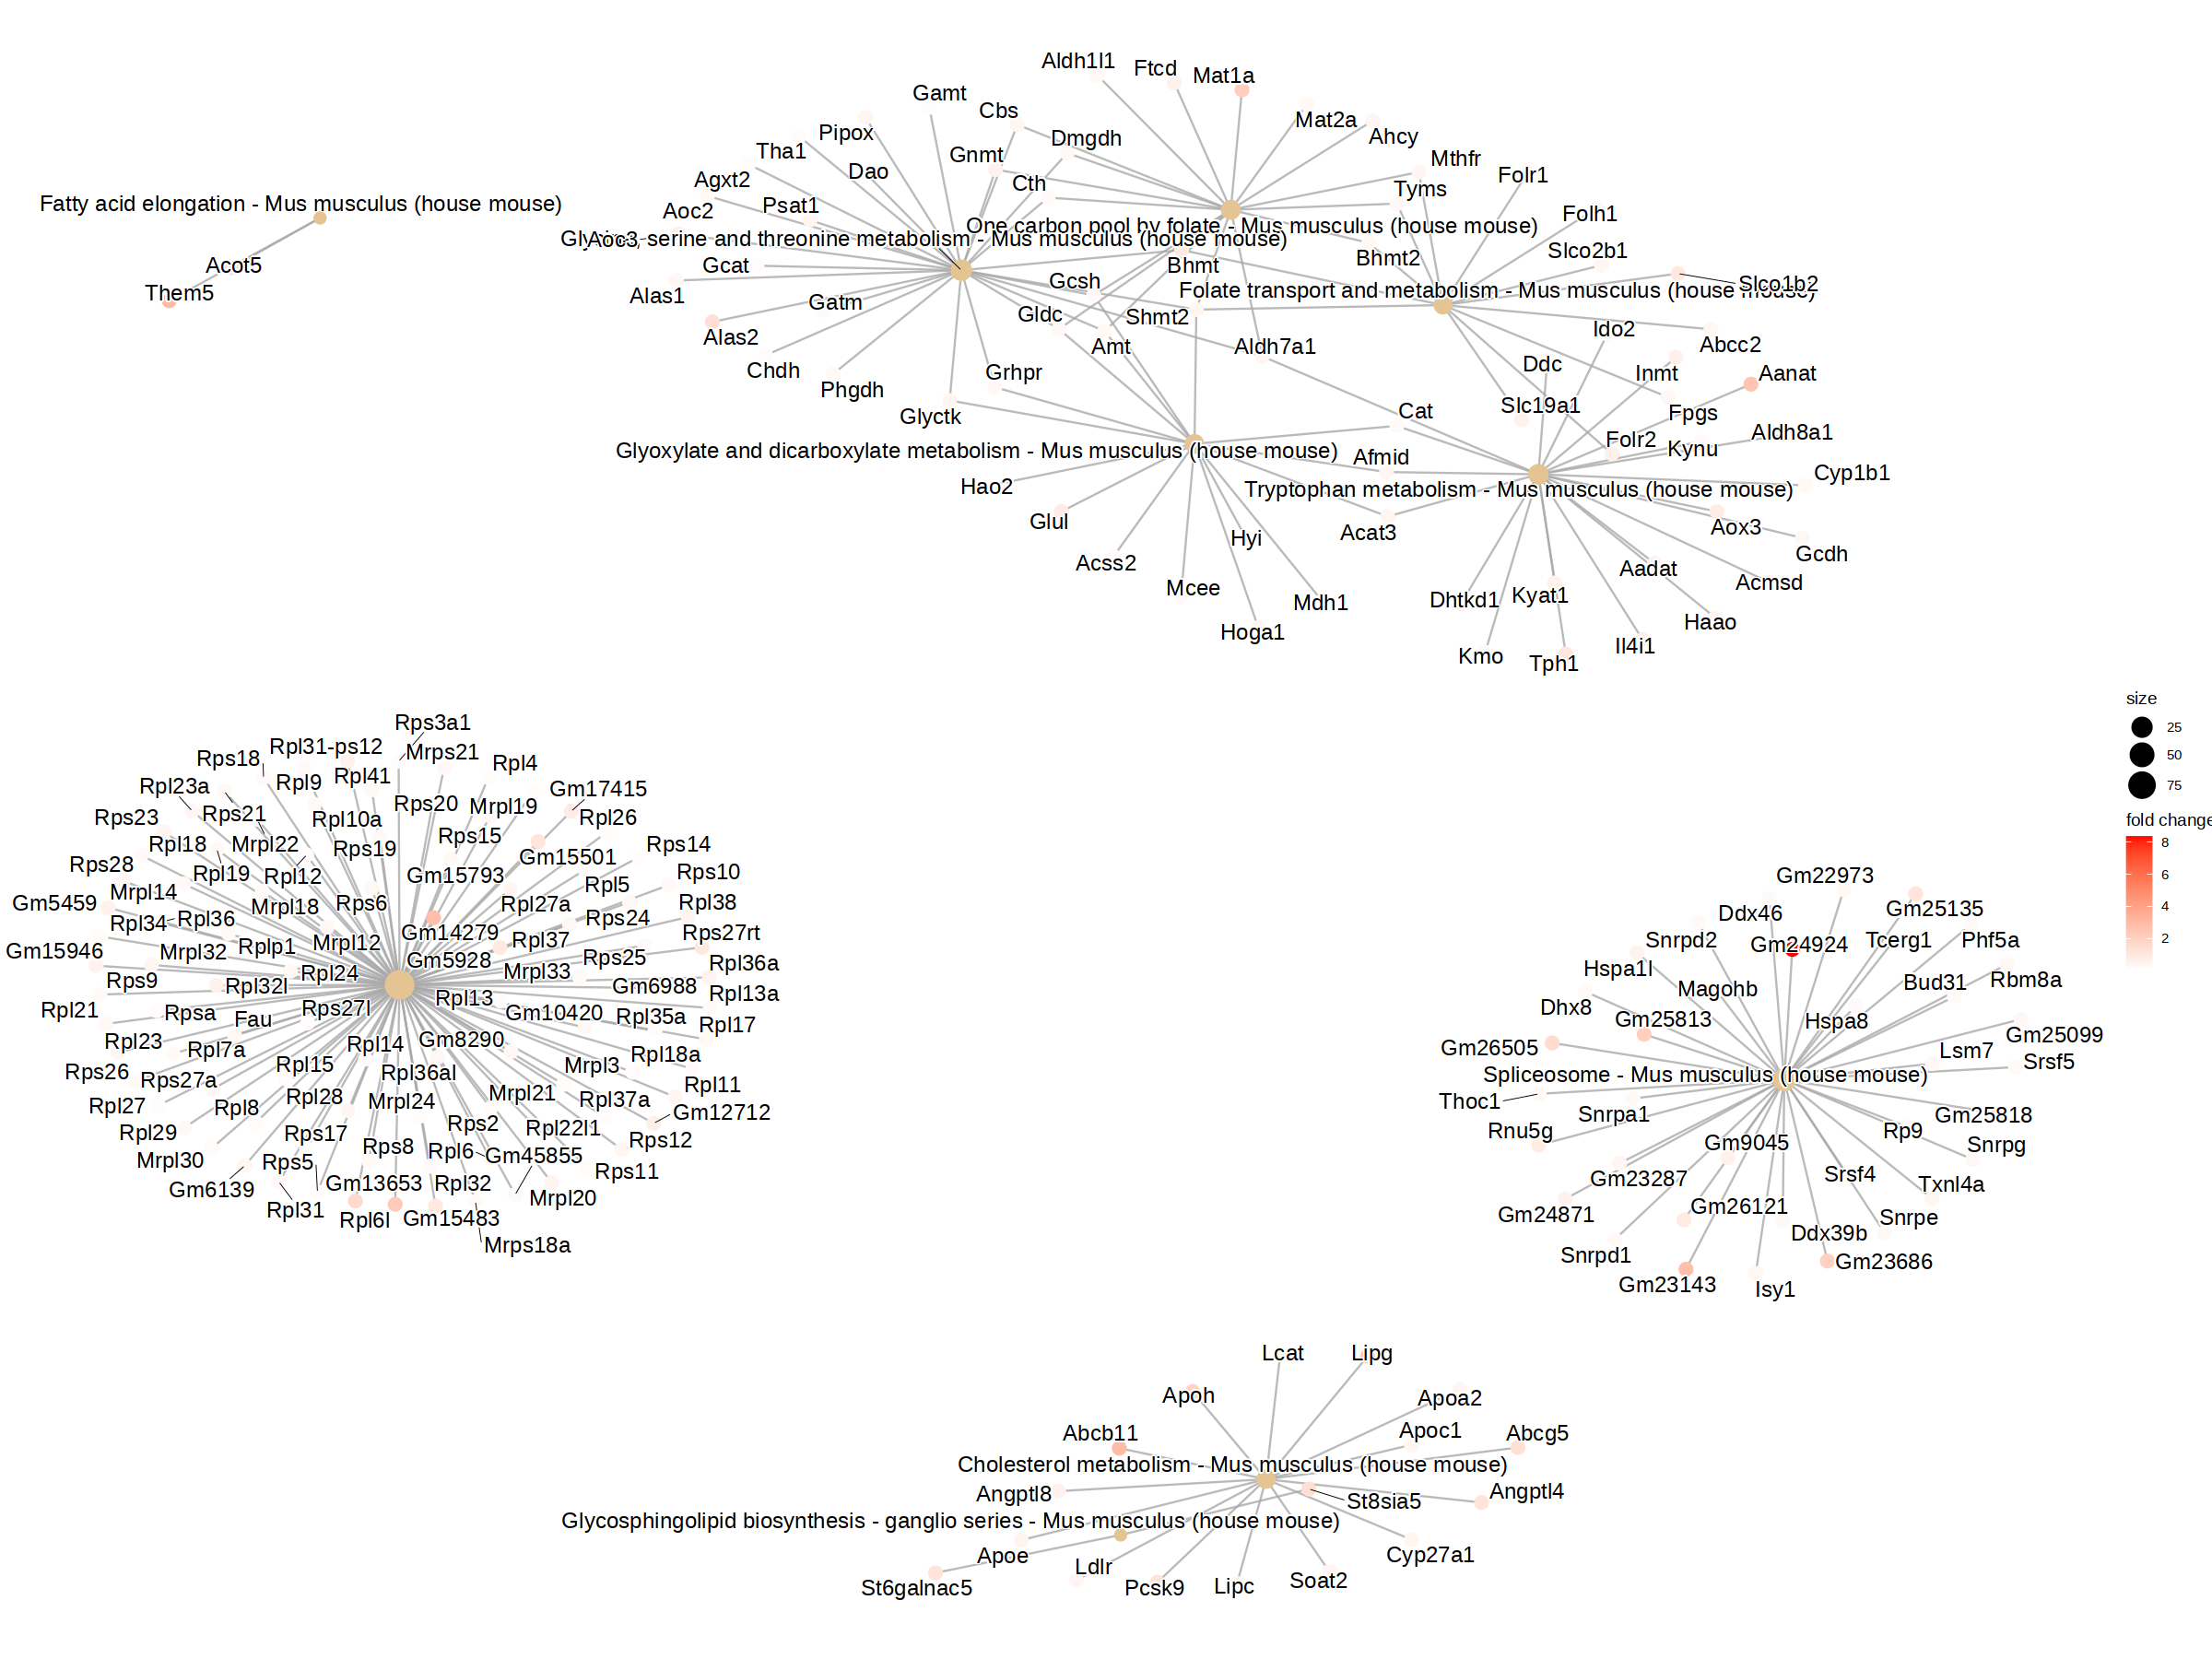

In [18]:
res_inter <- list()
d <- res_tableOE %>% data.frame()
d$SYMBOL <- rownames(d)

# Map SYMBOL to ENTREZID using org.Mm.eg.db and merge results with d
gene_ids <- bitr(d$SYMBOL, fromType = "SYMBOL", toType = "ENTREZID", OrgDb = org.Mm.eg.db)
d <- merge(d, gene_ids, by = "SYMBOL")
deg <- d[, c('ENTREZID', 'log2FoldChange')]
deg <- deg[!duplicated(deg), ]  # Remove duplicates
# Sort by log2FoldChange in the specified order
deg_data <- deg[order(deg$log2FoldChange, decreasing = TRUE), ]
deg_vector <- setNames(deg_data$log2FoldChange, deg_data$ENTREZID)
  
# Perform enrichment analysis (CC, BP, MF, KEGG, MKEGG) 
if (length(res_inter) == 0) {
    res_inter <<- list(
#       CC = gseGO(geneList = deg_vector, pvalueCutoff = 1, keyType = "ENTREZID", OrgDb = org.Mm.eg.db, ont = "CC"),
#       BP = gseGO(geneList = deg_vector, pvalueCutoff = 1, keyType = "ENTREZID", OrgDb = org.Mm.eg.db, ont = "BP"),
#       MF = gseGO(geneList = deg_vector, pvalueCutoff = 1, keyType = "ENTREZID", OrgDb = org.Mm.eg.db, ont = "MF"),
#       MKEGG = gseMKEGG(geneList = deg_vector, pvalueCutoff = 1, organism = 'mmu', keyType = 'ncbi-geneid'),
      KEGG = gseKEGG(geneList = deg_vector, pvalueCutoff = 1, organism = 'mmu', keyType = 'ncbi-geneid')
    )
  }
perform_gsea_and_plot <- function(deg_data, sort_desc = TRUE, file_name = "GSEA_plot.pdf", top_n = 10) {
  kk <- setReadable(res_inter[['KEGG']], OrgDb = org.Mm.eg.db, keyType = 'ENTREZID')
  selected_categories <- kk$Description[order(kk$NES, decreasing = sort_desc)][1:top_n]
  
  # Plot and save cnetplot
  options(repr.plot.width = 20, repr.plot.height = 15)
  plot <- cnetplot(kk, foldChange = deg_vector, showCategory = selected_categories, circular = FALSE, max.overlaps = 2000)
  print(plot)
  pdf(file_name, width = 20, height = 15)
  print(plot)
  dev.off()
  return(selected_categories) 
}

selected_categories1=perform_gsea_and_plot(deg_data, sort_desc = FALSE, file_name = "fig/GSEA_downReg.pdf")
selected_categories2=perform_gsea_and_plot(deg_data, sort_desc = TRUE, file_name = "fig/GSEA_upReg.pdf")


In [19]:
gsea_df <- as.data.frame(res_inter[['KEGG']]@result)
top_categories <- gsea_df[gsea_df$Description %in% c(selected_categories1,selected_categories2), ]

plot=ggplot(top_categories, aes(x = reorder(Description, NES), y = NES)) +
    geom_bar(stat = "identity", fill = "steelblue") +
    coord_flip() +
    labs(title = "GSEA Enriched Pathways", x = "Pathway", y = "Normalized Enrichment Score") +
    theme_minimal()
pdf('fig/GSEA_barplot_Top10.pdf', width = 8, height = 6)
print(plot)
dev.off()


png 
  2

# Transcript Expression


In the following, we will plot the expression of Wt1 and Wt1os transcripts.

reading in files with read_tsv

1 
2 
3 
4 
5 
6 




[1] TRUE

png 
  2

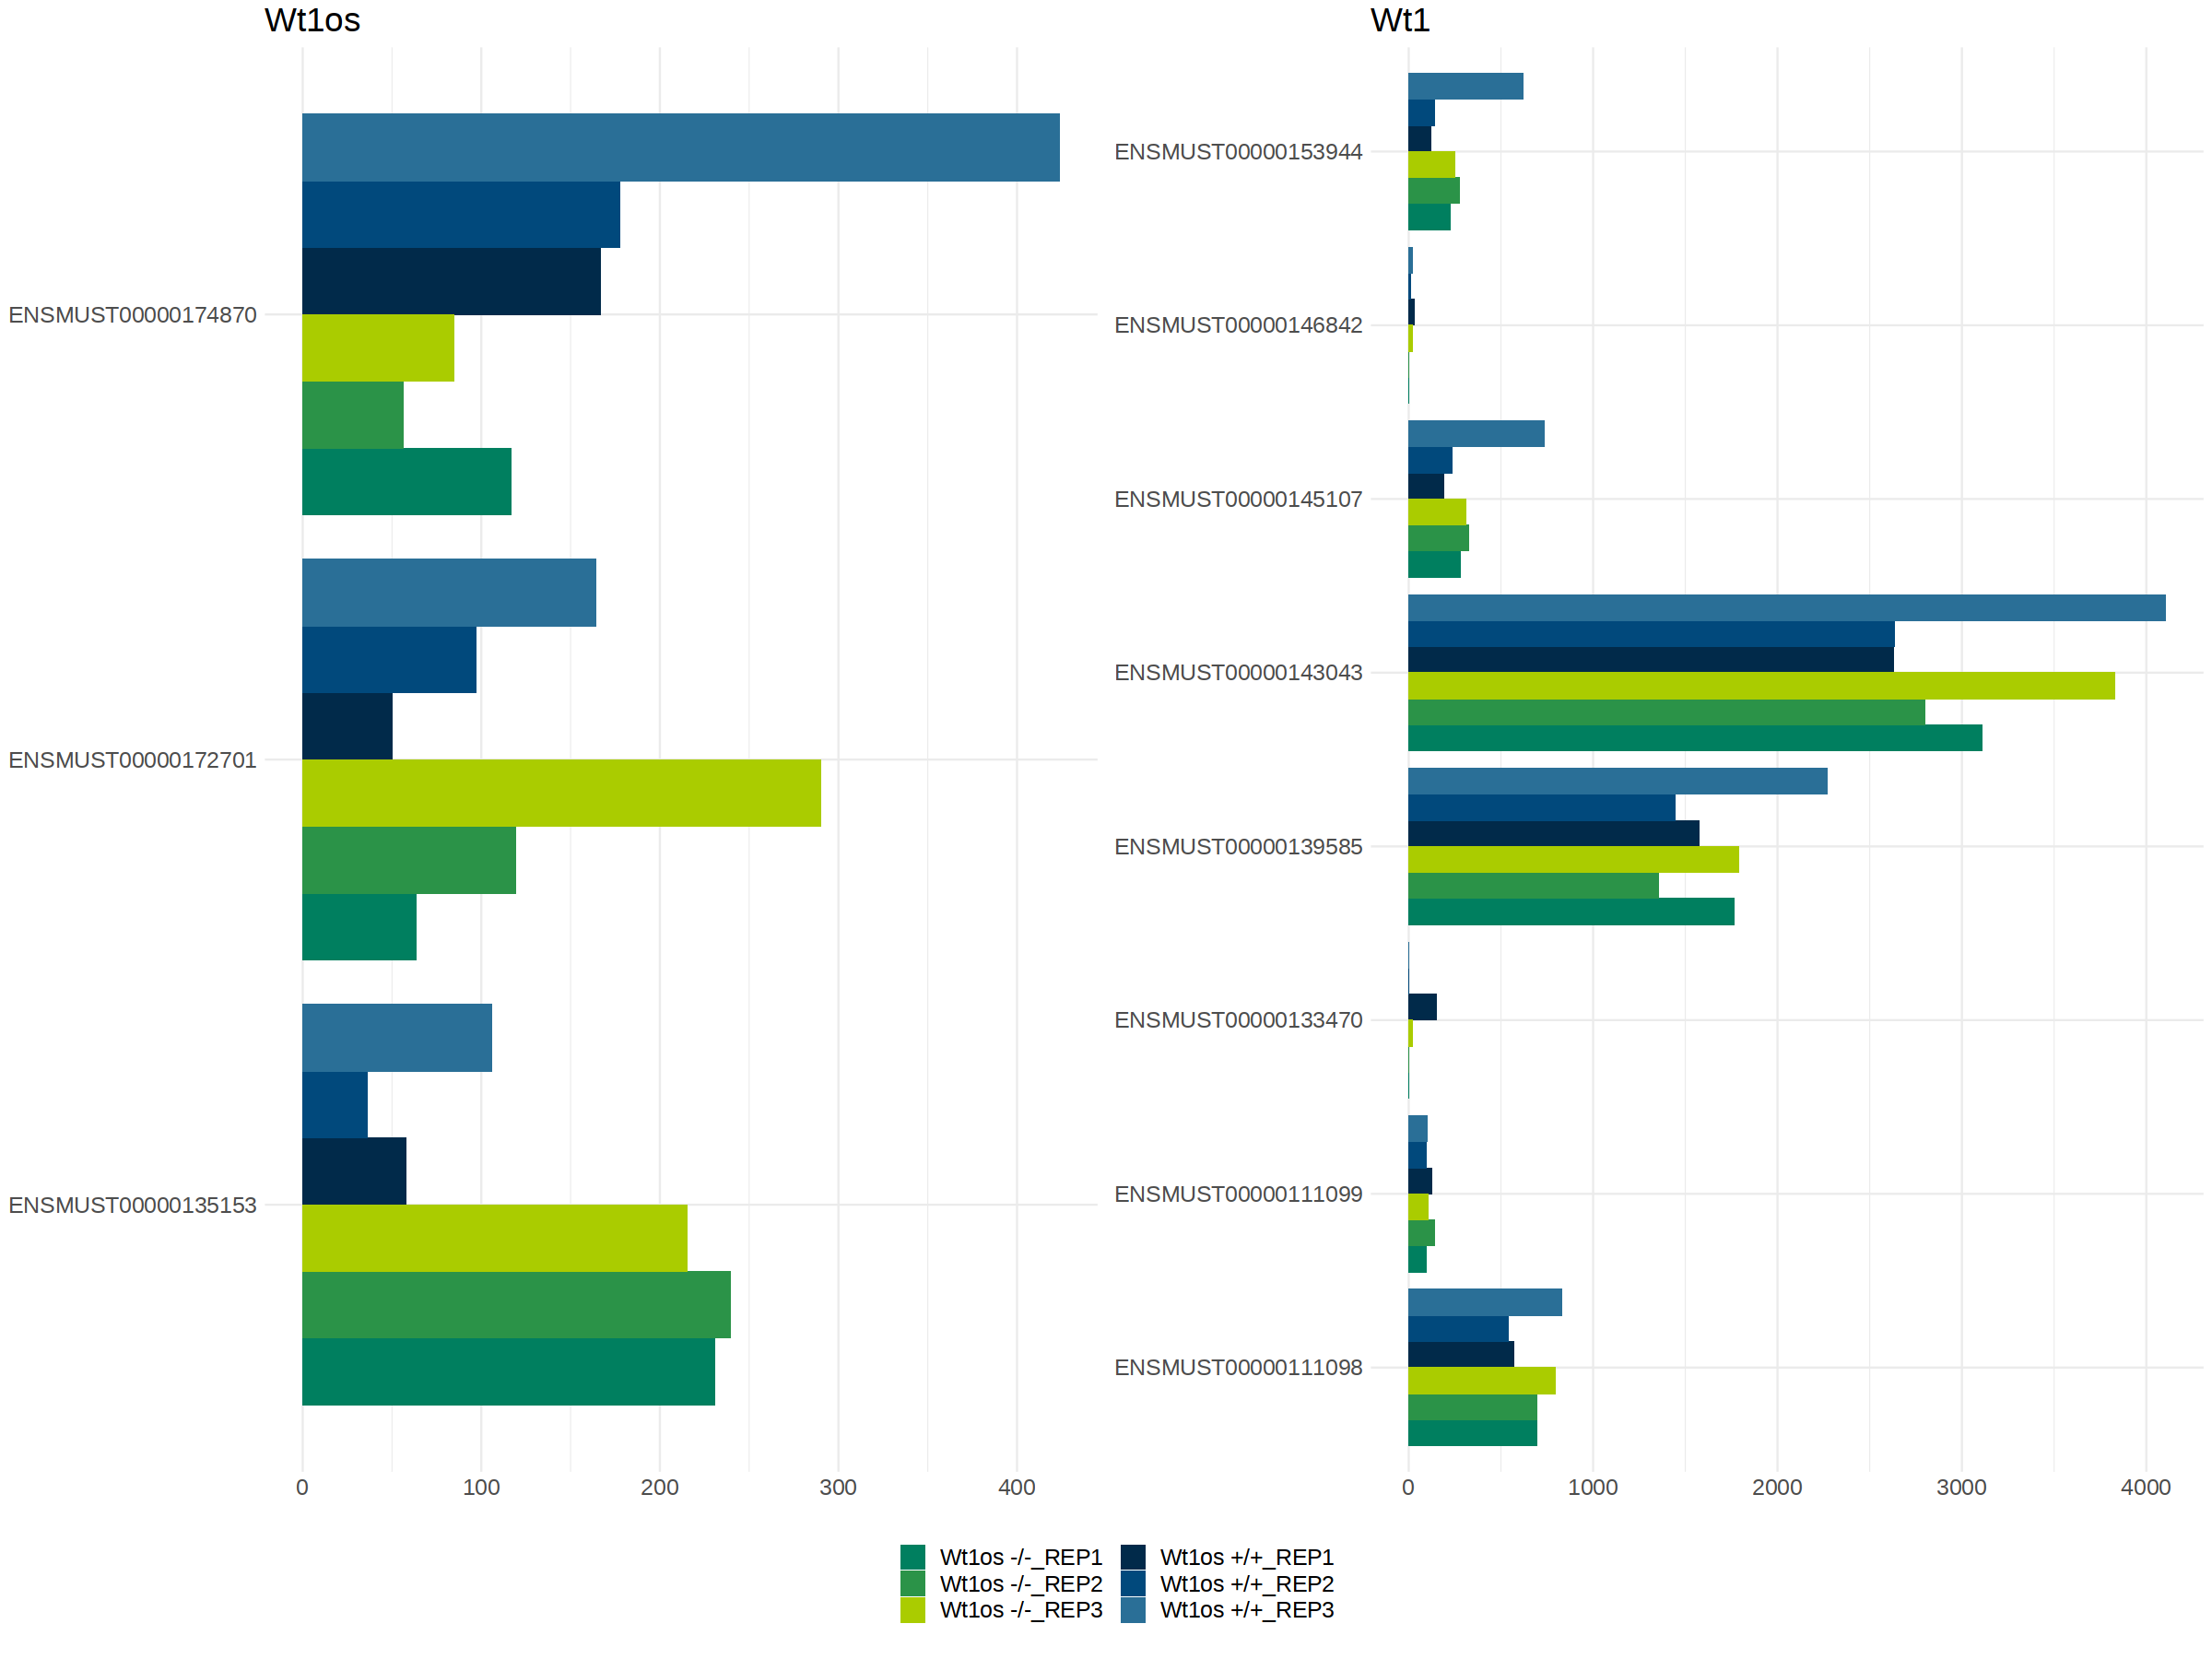

In [20]:
# Import transcript-level data using tximport
txi <- tximport(
  files,
  type = "salmon",
  tx2gene = tx2gene[, 1:2],
  txIn = TRUE,
  txOut = TRUE,
  countsFromAbundance = "dtuScaledTPM"
)

# Filter counts, keeping only transcripts with non-zero counts
cts <- txi$counts
cts <- cts[rowSums(cts) > 0, ]
txdf.sub <- tx2gene[match(rownames(cts), tx2gene$TXNAME), ]
all(rownames(cts) == txdf.sub$TXNAME)
counts <- data.frame(gene_id = txdf.sub$GENEID, feature_id = txdf.sub$TXNAME, cts)

# Define color palette for plotting
color_palette <- c(
      "#007F5F", "#2B9348", "#AACC00",   # Light Red
  "#012A4A", "#01497C", "#2A6F97"    # Light Blue

#   "#e41a1c",   # Dark Red
#   "#FF5733",   # Medium Red
#   "#FF7F50",   # Light Red
#   "#005BAC",   # Dark Blue
#   "#0077B3",   # Medium Blue
#   "#00A3E0"    # Light Blue
)

create_bar_plot <- function(data, title) {
  melted_data <- melt(data, id.vars = c('gene_id', 'feature_id'))
  melted_data$variable <- gsub("CONTROL", "Wt1os +/+", melted_data$variable)
  melted_data$variable <- gsub("KO", "Wt1os -/-", melted_data$variable)
  p <- ggplot(melted_data, aes(x = feature_id, y = value, fill = variable)) +
    geom_bar(stat = "identity", position = "dodge") +
    coord_flip() +
    scale_fill_manual(values = color_palette) +  # Custom color palette
    ggtitle(title) +
    theme_minimal() +
    theme(
      legend.position = "bottom",
      axis.title.x = element_blank(),
      axis.title.y = element_blank(),
      text = element_text(size = 18)
    ) +
    guides(fill = guide_legend(title = NULL, ncol = 2))  # Adjust legend

  return(p)
}

# Create datasets and bar plots for specified transcripts
dat1 <- counts[c('ENSMUST00000135153', 'ENSMUST00000172701', 'ENSMUST00000099647',
                 'ENSMUST00000174870', 'ENSMUST00000245064'), ]
dat1 <- dat1[!is.na(dat1$gene_id), ]
p1 <- create_bar_plot(dat1, 'Wt1os')

dat2 <- counts[c('ENSMUST00000143043', 'ENSMUST00000146842', 'ENSMUST00000133470',
                 'ENSMUST00000139585', 'ENSMUST00000145107', 'ENSMUST00000111098',
                 'ENSMUST00000111099', 'ENSMUST00000153944'), ]
dat2 <- dat2[!is.na(dat2$gene_id), ]
p2 <- create_bar_plot(dat2, 'Wt1')

# Combine plots with a shared legend
combined_plot <- plot_grid(
  p1 + theme(legend.position = "none"),  
  p2 + theme(legend.position = "none"),   
  align = 'h', ncol = 2, rel_widths = c(1, 1)
)

legend <- get_legend(p1 + theme(legend.position = "bottom"))
final_plot <- plot_grid(combined_plot, legend, ncol = 1, rel_heights = c(1, 0.1))
final_plot
pdf("fig/DTU_barplots.pdf", width = 14, height = 10)
print(final_plot)
dev.off()
